In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

def list_samples(images_dir):
    """
    images_dir içindeki tüm .npy dosyalarının adlarını döner.
    """
    samples = sorted([f for f in os.listdir(images_dir) if f.endswith(".npy")])
    for i, name in enumerate(samples):
        print(f"{i:3d}: {name}")
    return samples

def display_sample(sample_name, images_dir, masks_dir, cmap_image="gray", cmap_mask="nipy_spectral"):
    """
    Verilen sample_name ile hem image hem mask dosyasını yükler ve yanyana gösterir.
    
    Args:
        sample_name (str): Örneğin "ToothFairy2F_009_0000_upper_slice_58.npy"
        images_dir   (str): Görüntülerin bulunduğu klasör
        masks_dir    (str): Maskelerin bulunduğu klasör
        cmap_image   (str): Görüntü için matplotlib cmap (default "gray")
        cmap_mask    (str): Maske için matplotlib cmap (default "nipy_spectral")
    """
    img_path  = os.path.join(images_dir, sample_name)
    msk_path  = os.path.join(masks_dir,  sample_name)
    
    if not os.path.exists(img_path):
        raise FileNotFoundError(f"Image not found: {img_path}")
    if not os.path.exists(msk_path):
        raise FileNotFoundError(f"Mask not found:  {msk_path}")
    
    img = np.load(img_path)
    msk = np.load(msk_path)
    
    plt.figure(figsize=(10,5))
    plt.subplot(1,2,1)
    plt.imshow(img, cmap=cmap_image)
    plt.title(f"Image: {sample_name}")
    plt.axis("off")
    
    plt.subplot(1,2,2)
    plt.imshow(msk, cmap=cmap_mask, vmin=0, vmax=np.max(msk))
    plt.title(f"Mask:  {sample_name}")
    plt.axis("off")
    
    plt.tight_layout()
    plt.show()


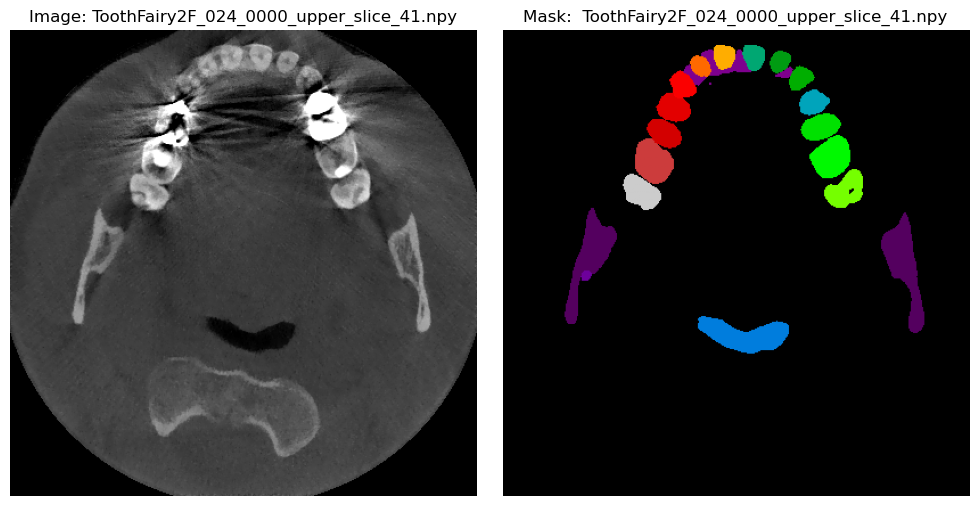

In [ ]:
images_dir = r"C:\Users\user\Desktop\TeethSegmentation\2D_dataset\test\images"
masks_dir  = r"C:\Users\user\Desktop\TeethSegmentation\2D_dataset\test\masks"

# 1) Elindeki sample isimlerini görmek için:
# samples = list_samples(images_dir)

# 2) Mesela 10. sample’ı göstermek için:
# display_sample(samples[4], images_dir, masks_dir)

# 3) Ya da doğrudan isimle:
display_sample(
    "ToothFairy2F_029_0000_upper_slice_56.npy",
    images_dir, masks_dir
)